In [5]:
# %% Cell 1 - Setup
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import numpy as np
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [6]:
# %% Cell 2 - Markov chain functions

block_size = 512
batch_size = 16
learning_rate = 0.001
weight_decay = 1e-3
dropout = 0.0
vocabulary_size = 2
eval_iters = 200
eval_interval = 500

def generate_transition_matrix(order, seed):
    if seed is not None:
        torch.manual_seed(seed)
    n_states = 2 ** order
    matrix = torch.rand((n_states, 2))
    row_sums = matrix.sum(dim=1, keepdim=True)
    matrix = matrix / row_sums
    return matrix

def generate_sequence(transition_matrix, order, length, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    sequence = torch.zeros(length, dtype=torch.long)
    for i in range(order):
        sequence[i] = torch.randint(0, 2, (1,))
    for i in range(order, length):
        state_idx = 0
        for j in range(order):
            state_idx = state_idx * 2 + sequence[i - order + j]
        probs = transition_matrix[int(state_idx)]
        sequence[i] = torch.bernoulli(probs[1])
    return sequence.tolist()

def estimate_matrix(sequence, order):
    num_states = 2 ** order
    counts = torch.zeros((num_states, 2))
    for i in range(len(sequence) - order):
        state = sequence[i:i + order]
        state_idx = int(''.join(map(str, state)), 2)
        next_bit = sequence[i + order]
        counts[state_idx, next_bit] += 1
    row_sums = counts.sum(dim=1, keepdim=True)
    row_sums[row_sums == 0] = 2
    return counts / row_sums

def generate_training_data(transition_matrix, order, sequence_length, num_sequences):
    sequences = []
    for i in range(num_sequences):
        sequence = generate_sequence(transition_matrix, order, sequence_length, i)
        sequences.append(torch.tensor(sequence, dtype=torch.long))
    return sequences

def get_batch(sequences, split='train'):
    n = int(0.9 * len(sequences))
    data = sequences[:n] if split == 'train' else sequences[n:]
    while True:
        seq_indices = torch.randint(len(data), (batch_size,))
        x_batch, y_batch = [], []
        for idx in seq_indices:
            sequence = data[idx]
            if len(sequence) >= block_size + 1:
                start_idx = torch.randint(0, len(sequence) - block_size, (1,))
                x_batch.append(sequence[start_idx:start_idx + block_size])
                y_batch.append(sequence[start_idx + 1:start_idx + block_size + 1])
        if len(x_batch) > 0:
            return torch.stack(x_batch).to(device), torch.stack(y_batch).to(device)

@torch.no_grad()
def estimate_loss(model, sequences):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(sequences, split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

def kl_divergence(chain1, chain2, epsilon=1e-10):
    defined_states = torch.sum(chain2, dim=1) > 0
    p = chain1[defined_states] + epsilon
    q = chain2[defined_states] + epsilon
    p = p / p.sum(dim=1, keepdim=True)
    q = q / q.sum(dim=1, keepdim=True)
    return torch.sum(p * torch.log(p / q)).item()

def mean_error(chain1, chain2):
    defined_states = torch.sum(chain2, dim=1) > 0
    return torch.mean(torch.abs(chain1[defined_states] - chain2[defined_states])).item()

In [7]:
# %% Cell 3 - Transformer model

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * C ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class BinaryTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocabulary_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

print("Model defined.")

Model defined.


In [ ]:
# %% Cell 4 - Evaluate all exp2 models

def evaluate_model(model_path, order, output_lengths=[500, 1000, 2000, 5000], num_test_seeds=10):
    checkpoint = torch.load(model_path, map_location=device)
    transition_matrix = torch.tensor(checkpoint['transition_matrix'])
    config = checkpoint['config']
    
    global n_head, n_layer, n_embd
    n_head = config['n_head']
    n_layer = config['n_layer']
    n_embd = config['n_embd']
    
    model = BinaryTransformer().to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    
    results = []
    for output_length in output_lengths:
        klds, maes = [], []
        for seed in range(200, 200 + num_test_seeds):
            context = generate_sequence(transition_matrix, order, 50, seed)
            context_tensor = torch.tensor(context, dtype=torch.long).unsqueeze(0).to(device)
            with torch.no_grad():
                generated = model.generate(context_tensor, output_length)
            output = generated.tolist()[0][50:]
            estimated = estimate_matrix(output, order)
            klds.append(kl_divergence(transition_matrix, estimated))
            maes.append(mean_error(transition_matrix, estimated))
        results.append({
            'output_length': output_length,
            'kld_mean': np.mean(klds), 'kld_std': np.std(klds),
            'mae_mean': np.mean(maes), 'mae_std': np.std(maes),
        })
    
    return {'config': config, 'entropy_rate': config['entropy_rate'],
            'final_loss': checkpoint['history']['train'][-1], 'results': results}

models_dir = os.path.expanduser('../models/exp2')
results_dir = os.path.expanduser('../results/model_scaling')
Path(results_dir).mkdir(parents=True, exist_ok=True)

all_eval = {}

for size in ['moritz', 'medium', 'large']:
    all_eval[size] = {}
    for order in [1, 2, 3, 4, 5, 6]:
        model_dir = Path(f"{models_dir}/{size}/order{order}")
        model_files = sorted(model_dir.glob('*.pt'))
        
        print(f"{size} — Order {order} ({len(model_files)} models)")
        all_eval[size][order] = []
        
        for i, mf in enumerate(model_files):
            print(f"  Model {i+1}/{len(model_files)}", end=" ")
            result = evaluate_model(mf, order)
            kld = result['results'][1]['kld_mean']  # output_length=1000
            print(f"KLD@1000={kld:.4f}")
            all_eval[size][order].append(result)

# Save
save_data = {}
for size in all_eval:
    save_data[size] = {}
    for order in all_eval[size]:
        save_data[size][str(order)] = [
            {'config': r['config'], 'entropy_rate': r['entropy_rate'],
             'final_loss': r['final_loss'], 'results': r['results']}
            for r in all_eval[size][order]
        ]

with open(f'{results_dir}/evaluation_results.json', 'w') as f:
    json.dump(save_data, f, indent=2)

print("\n\nALL EVALUATION COMPLETE!")

moritz — Order 1 (10 models)
  Model 1/10 KLD@1000=0.0027
  Model 2/10 KLD@1000=0.0027
  Model 3/10 KLD@1000=0.0021
  Model 4/10 KLD@1000=0.0028
  Model 5/10 KLD@1000=0.0073
  Model 6/10 

In [10]:
import json

with open(os.path.expanduser('../results/model_scaling/evaluation_results.json'), 'r') as f:
    data = json.load(f)

for size in data:
    for order in data[size]:
        print(f"{size} order {order}: {len(data[size][order])} models evaluated")

moritz order 1: 10 models evaluated
moritz order 2: 10 models evaluated
moritz order 3: 10 models evaluated
moritz order 4: 10 models evaluated
moritz order 5: 10 models evaluated
moritz order 6: 10 models evaluated
medium order 1: 10 models evaluated
medium order 2: 10 models evaluated
medium order 3: 10 models evaluated
medium order 4: 10 models evaluated
medium order 5: 10 models evaluated
medium order 6: 10 models evaluated
large order 1: 10 models evaluated
large order 2: 10 models evaluated
large order 3: 10 models evaluated
large order 4: 10 models evaluated
large order 5: 10 models evaluated
large order 6: 10 models evaluated


In [11]:
# %% Comparison table: Moritz vs Medium vs Large at output_length=1000

print("KL DIVERGENCE — Model Capacity Comparison (output_length=1000)")
print(f"{'Order':<7} {'Moritz KLD':<22} {'Medium KLD':<22} {'Large KLD':<22}")
print("-" * 73)

for order in ['1', '2', '3', '4', '5', '6']:
    vals = {}
    for size in ['moritz', 'medium', 'large']:
        v = []
        for model_result in data[size][order]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    v.append(r['kld_mean'])
        vals[size] = v
    
    print(f"{order:<7} {np.mean(vals['moritz']):.4f} ± {np.std(vals['moritz']):.4f}   "
          f"{np.mean(vals['medium']):.4f} ± {np.std(vals['medium']):.4f}   "
          f"{np.mean(vals['large']):.4f} ± {np.std(vals['large']):.4f}")

print(f"\n\nMAE — Model Capacity Comparison (output_length=1000)")
print(f"{'Order':<7} {'Moritz MAE':<22} {'Medium MAE':<22} {'Large MAE':<22}")
print("-" * 73)

for order in ['1', '2', '3', '4', '5', '6']:
    vals = {}
    for size in ['moritz', 'medium', 'large']:
        v = []
        for model_result in data[size][order]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    v.append(r['mae_mean'])
        vals[size] = v
    
    print(f"{order:<7} {np.mean(vals['moritz']):.4f} ± {np.std(vals['moritz']):.4f}   "
          f"{np.mean(vals['medium']):.4f} ± {np.std(vals['medium']):.4f}   "
          f"{np.mean(vals['large']):.4f} ± {np.std(vals['large']):.4f}")
    

KL DIVERGENCE — Model Capacity Comparison (output_length=1000)
Order   Moritz KLD             Medium KLD             Large KLD             
-------------------------------------------------------------------------
1       0.0033 ± 0.0015   0.0033 ± 0.0012   0.0030 ± 0.0015
2       0.0874 ± 0.0784   0.0243 ± 0.0203   0.0195 ± 0.0207
3       0.2708 ± 0.5833   0.0573 ± 0.0195   0.1433 ± 0.1006
4       0.8068 ± 0.5408   1.0850 ± 0.8280   1.2432 ± 0.9766
5       4.1398 ± 3.4041   4.0959 ± 3.6263   3.7396 ± 3.5635
6       22.8760 ± 9.4804   26.9113 ± 8.9999   24.3066 ± 8.5311


MAE — Model Capacity Comparison (output_length=1000)
Order   Moritz MAE             Medium MAE             Large MAE             
-------------------------------------------------------------------------
1       0.0188 ± 0.0031   0.0190 ± 0.0032   0.0181 ± 0.0034
2       0.0675 ± 0.0367   0.0331 ± 0.0127   0.0282 ± 0.0109
3       0.0519 ± 0.0250   0.0376 ± 0.0050   0.0545 ± 0.0244
4       0.0918 ± 0.0409   0.0641 ± 0.

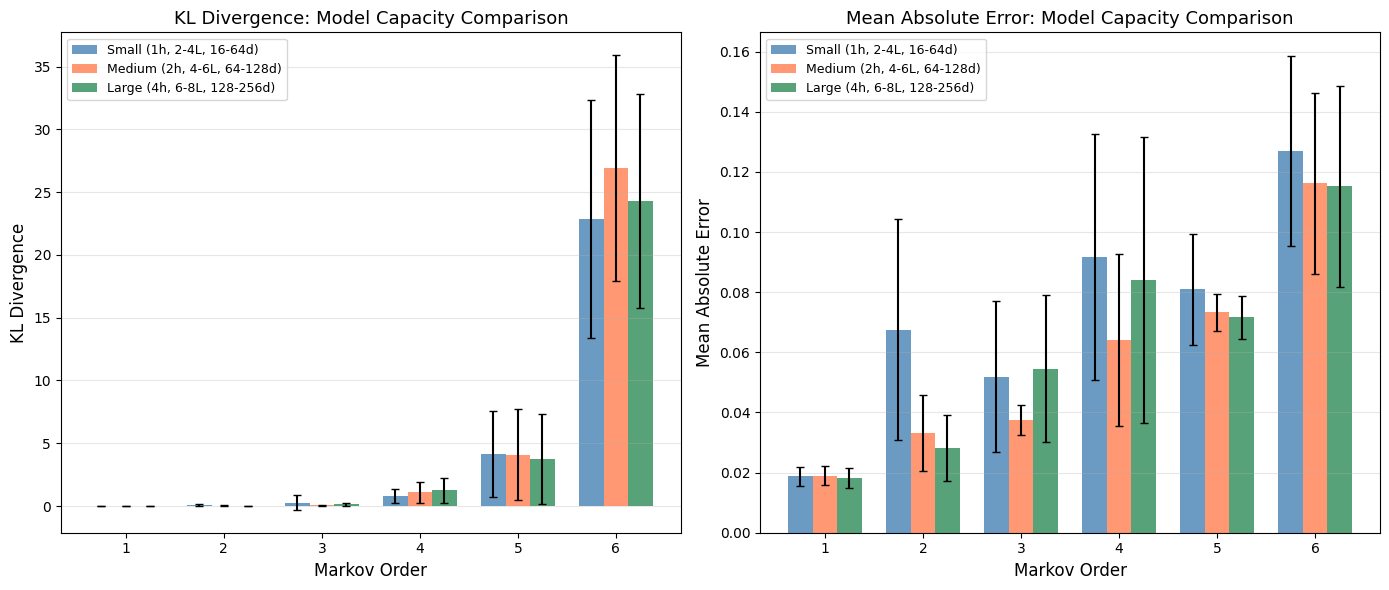

Plot saved!


In [12]:
# %% Plot: Model capacity comparison

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

orders = [1, 2, 3, 4, 5, 6]
colors = {'moritz': 'steelblue', 'medium': 'coral', 'large': 'seagreen'}

for ax, metric, label in [(axes[0], 'kld', 'KL Divergence'), (axes[1], 'mae', 'Mean Absolute Error')]:
    x = np.arange(len(orders))
    width = 0.25
    
    for i, size in enumerate(['moritz', 'medium', 'large']):
        means = []
        stds = []
        for order in orders:
            vals = []
            for model_result in data[size][str(order)]:
                for r in model_result['results']:
                    if r['output_length'] == 1000:
                        vals.append(r[f'{metric}_mean'])
            means.append(np.mean(vals))
            stds.append(np.std(vals))
        
        labels = {'moritz': 'Small (1h, 2-4L, 16-64d)', 
                  'medium': 'Medium (2h, 4-6L, 64-128d)',
                  'large': 'Large (4h, 6-8L, 128-256d)'}
        
        ax.bar(x + (i-1)*width, means, width, yerr=stds,
               label=labels[size], color=colors[size], capsize=3, alpha=0.8)
    
    ax.set_xlabel('Markov Order', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label}: Model Capacity Comparison', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(orders)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.expanduser('../plots/../plots/exp2_capacity_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

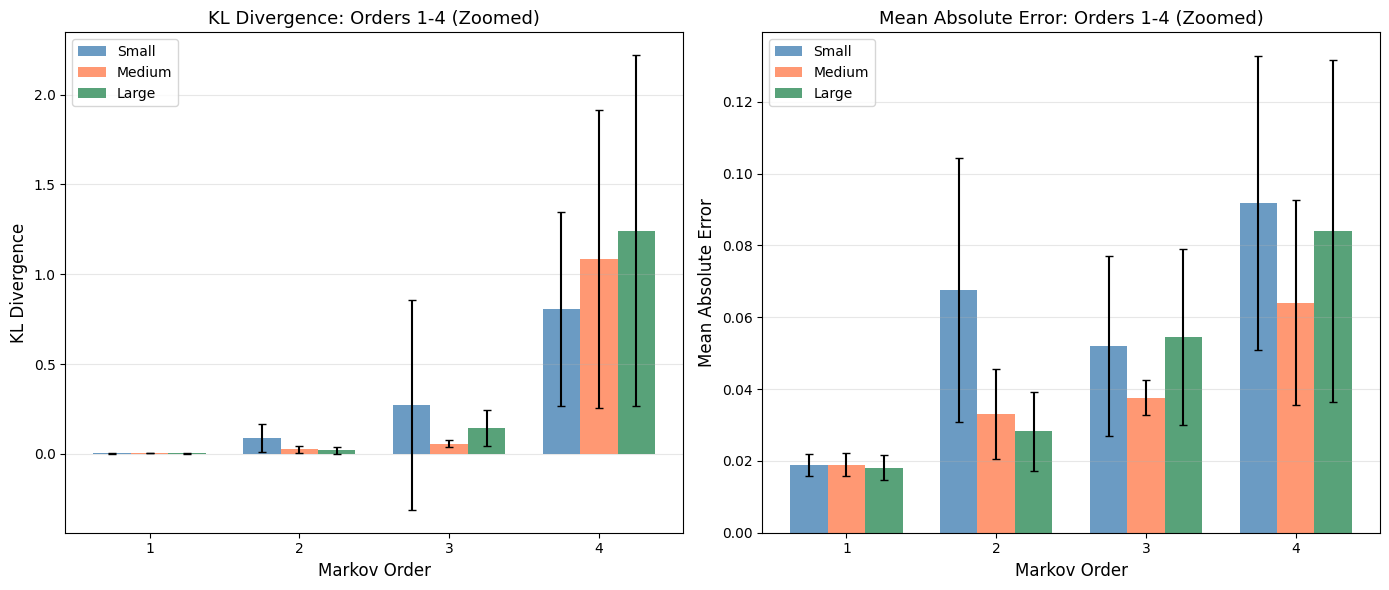

Plot saved!


In [13]:
# %% Plot: Zoomed into orders 1-4

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

orders_zoom = [1, 2, 3, 4]

for ax, metric, label in [(axes[0], 'kld', 'KL Divergence'), (axes[1], 'mae', 'Mean Absolute Error')]:
    x = np.arange(len(orders_zoom))
    width = 0.25
    
    for i, size in enumerate(['moritz', 'medium', 'large']):
        means = []
        stds = []
        for order in orders_zoom:
            vals = []
            for model_result in data[size][str(order)]:
                for r in model_result['results']:
                    if r['output_length'] == 1000:
                        vals.append(r[f'{metric}_mean'])
            means.append(np.mean(vals))
            stds.append(np.std(vals))
        
        labels = {'moritz': 'Small', 'medium': 'Medium', 'large': 'Large'}
        ax.bar(x + (i-1)*width, means, width, yerr=stds,
               label=labels[size], color=colors[size], capsize=3, alpha=0.8)
    
    ax.set_xlabel('Markov Order', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label}: Orders 1-4 (Zoomed)', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(orders_zoom)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.expanduser('../plots/../plots/exp2_zoomed_orders1to4.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")